<a href="https://colab.research.google.com/github/lahirunie-dulsara/EN4554-Assignment-2-on-CNNs/blob/main/CNN_DL_for_Vision.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EN4554 – Assignment 2 (CNNs):

**Name:** `Dulsara G.M.L.`  **Index No.:** `220146A`  
**GitHub:** `https://github.com/lahirunie-dulsara/EN4554-Assignment-2-on-CNNs`

In [1]:
# ============ COMMON SETUP (identical in every notebook) ============
import os, time, math, random, copy
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

SMOKE = bool(int(os.environ.get('SMOKE', '0')))   # 1 -> tiny synthetic data, only to check the code runs
SEED = 0

def seed_all(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_all()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.backends.cudnn.benchmark = True
print('device:', device, '| torch', torch.__version__, '| SMOKE =', SMOKE)

def load_cifar10(root='./data'):
    """45k train / 5k val split (fixed seed). Per-channel normalisation uses TRAINING statistics only.
    The official test set is never touched here (it is only loaded in Task 4)."""
    if SMOKE:
        g = torch.Generator().manual_seed(0)
        X = torch.rand(700, 3, 32, 32, generator=g); y = torch.randint(0, 10, (700,), generator=g); ntr = 600
    else:
        import torchvision
        ds = torchvision.datasets.CIFAR10(root, train=True, download=True)
        X = torch.from_numpy(ds.data).permute(0, 3, 1, 2).float() / 255.
        y = torch.tensor(ds.targets); ntr = 45000
    perm = torch.randperm(len(X), generator=torch.Generator().manual_seed(0))
    tr, va = perm[:ntr], perm[ntr:]
    mean = X[tr].mean((0, 2, 3), keepdim=True); std = X[tr].std((0, 2, 3), keepdim=True)
    Xn = (X - mean) / std
    return Xn[tr].to(device), y[tr].to(device), Xn[va].to(device), y[va].to(device), mean, std

Xtr, ytr, Xva, yva, MEAN, STD = load_cifar10()
print('train', tuple(Xtr.shape), 'val', tuple(Xva.shape))

# ---------------- data augmentation (all implemented by hand, on GPU, per-sample randomness) ----------------
def random_flip(x):
    m = torch.rand(x.size(0), device=x.device) < 0.5
    return torch.where(m[:, None, None, None], x.flip(3), x)

def random_crop(x, pad=4):
    B, C, H, W = x.shape
    xp = F.pad(x, (pad,) * 4)                      # zero padding == mean colour after normalisation
    i = torch.randint(0, 2 * pad + 1, (B,), device=x.device)
    j = torch.randint(0, 2 * pad + 1, (B,), device=x.device)
    ar = torch.arange(H, device=x.device)
    rows = (i[:, None] + ar)[:, None, :, None]
    cols = (j[:, None] + ar)[:, None, None, :]
    b = torch.arange(B, device=x.device)[:, None, None, None]
    c = torch.arange(C, device=x.device)[None, :, None, None]
    return xp[b, c, rows, cols]

def cutout(x, size=16):
    B, C, H, W = x.shape
    cy = torch.randint(0, H, (B,), device=x.device); cx = torch.randint(0, W, (B,), device=x.device)
    ys = torch.arange(H, device=x.device)[None, :, None]; xs = torch.arange(W, device=x.device)[None, None, :]
    y0 = (cy - size // 2)[:, None, None]; x0 = (cx - size // 2)[:, None, None]
    mask = (ys >= y0) & (ys < y0 + size) & (xs >= x0) & (xs < x0 + size)   # square clipped at the border
    return x.masked_fill(mask[:, None], 0.)

def mixup(x, y, alpha=0.4):
    lam = float(np.random.beta(alpha, alpha))
    idx = torch.randperm(x.size(0), device=x.device)
    return lam * x + (1 - lam) * x[idx], y, y[idx], lam

AUGS = {'flip': random_flip, 'crop': random_crop, 'cutout': cutout}

# ---------------- training / evaluation ----------------
@torch.no_grad()
def evaluate(model, X, y, bs=1000):
    model.eval(); loss = 0.; correct = 0
    for k in range(0, len(X), bs):
        out = model(X[k:k + bs]).float()
        loss += F.cross_entropy(out, y[k:k + bs], reduction='sum').item()
        correct += (out.argmax(1) == y[k:k + bs]).sum().item()
    return loss / len(X), correct / len(X)

def cosine_warmup(opt, total_steps, warmup_steps=0):
    def f(s):
        if s < warmup_steps: return (s + 1) / warmup_steps
        p = (s - warmup_steps) / max(1, total_steps - warmup_steps)
        return 0.5 * (1 + math.cos(math.pi * p))
    return torch.optim.lr_scheduler.LambdaLR(opt, f)

def train_model(model, opt, epochs, Xtr=Xtr, ytr=ytr, Xva=Xva, yva=yva, bs=128, augs=(), mixup_alpha=0.,
                label_smoothing=0., sched=None, amp=False, eval_train=False, verbose=True):
    """Generic loop. 'train_loss' is the running mean of the (augmented) minibatch loss;
    'train_acc' (if eval_train) is measured in eval mode on the CLEAN training set."""
    model.to(device)
    use_amp = amp and device.type == 'cuda'
    scaler = torch.amp.GradScaler('cuda', enabled=use_amp)
    h = dict(train_loss=[], train_acc=[], val_loss=[], val_acc=[], diverged=False)
    n = len(Xtr)
    for ep in range(epochs):
        model.train(); t0 = time.time(); run = 0.; seen = 0
        perm = torch.randperm(n, device=device)
        for k in range(0, n - bs + 1, bs):
            idx = perm[k:k + bs]; x, y = Xtr[idx], ytr[idx]
            for a in augs: x = AUGS[a](x)
            with torch.autocast('cuda', dtype=torch.float16, enabled=use_amp):
                if mixup_alpha > 0:
                    x, ya, yb, lam = mixup(x, y, mixup_alpha); out = model(x)
                    loss = lam * F.cross_entropy(out, ya, label_smoothing=label_smoothing) + \
                           (1 - lam) * F.cross_entropy(out, yb, label_smoothing=label_smoothing)
                else:
                    out = model(x); loss = F.cross_entropy(out, y, label_smoothing=label_smoothing)
            if not torch.isfinite(loss):
                h['diverged'] = True; break
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            if sched is not None: sched.step()
            run += loss.item() * bs; seen += bs
        if h['diverged']:
            print(f'  diverged at epoch {ep+1}'); break
        h['train_loss'].append(run / seen)
        vl, va = evaluate(model, Xva, yva); h['val_loss'].append(vl); h['val_acc'].append(va)
        if eval_train: h['train_acc'].append(evaluate(model, Xtr, ytr)[1])
        if verbose:
            print(f'  ep {ep+1:3d}/{epochs} train_loss {h["train_loss"][-1]:.4f} val_loss {vl:.4f} '
                  f'val_acc {va:.4f}' + (f' train_acc {h["train_acc"][-1]:.4f}' if eval_train else '') +
                  f' ({time.time()-t0:.1f}s)')
    return h

def count_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

# ---------------- models ----------------
class SmallCNN(nn.Module):
    """3 x [conv3x3 - (BN) - ReLU - maxpool - (dropout)] followed by a 2-layer classifier."""
    def __init__(self, bn=False, dropout=False, widths=(32, 64, 128)):
        super().__init__()
        L = []; cin = 3
        for w in widths:
            L += [nn.Conv2d(cin, w, 3, padding=1, bias=not bn)]
            if bn: L += [nn.BatchNorm2d(w)]
            L += [nn.ReLU(inplace=True), nn.MaxPool2d(2)]
            if dropout: L += [nn.Dropout(0.25)]
            cin = w
        self.features = nn.Sequential(*L)
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(widths[-1] * 16, 256), nn.ReLU(inplace=True),
                                        nn.Dropout(0.5) if dropout else nn.Identity(), nn.Linear(256, 10))
    def forward(self, x): return self.classifier(self.features(x))

class Block(nn.Module):
    """Two 3x3 conv-BN layers. residual=False removes ONLY the shortcut (plain network)."""
    def __init__(self, cin, cout, stride, residual):
        super().__init__()
        self.conv1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False); self.bn1 = nn.BatchNorm2d(cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False);     self.bn2 = nn.BatchNorm2d(cout)
        self.residual = residual
        self.short = (nn.Sequential(nn.Conv2d(cin, cout, 1, stride, bias=False), nn.BatchNorm2d(cout))
                      if residual and (stride != 1 or cin != cout) else nn.Identity())
    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.residual: out = out + self.short(x)
        return F.relu(out)

class CifarNet(nn.Module):
    """CIFAR-style net of depth 6n+2: conv3x3 -> 3 stages x n blocks -> global avg pool -> linear."""
    def __init__(self, n, residual=True, widths=(16, 32, 64), num_classes=10):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, widths[0], 3, 1, 1, bias=False), nn.BatchNorm2d(widths[0]), nn.ReLU(inplace=True))
        blocks = []; cin = widths[0]
        for s, w in enumerate(widths):
            for b in range(n):
                blocks.append(Block(cin, w, 2 if (b == 0 and s > 0) else 1, residual)); cin = w
        self.blocks = nn.Sequential(*blocks)
        self.fc = nn.Linear(widths[-1], num_classes)
        for m in self.modules():                      # Kaiming initialisation
            if isinstance(m, nn.Conv2d): nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, nn.Linear): nn.init.kaiming_normal_(m.weight, nonlinearity='relu'); nn.init.zeros_(m.bias)
    def forward(self, x):
        x = self.blocks(self.stem(x))
        return self.fc(F.adaptive_avg_pool2d(x, 1).flatten(1))


device: cuda | torch 2.11.0+cu128 | SMOKE = False


100%|██████████| 170M/170M [35:37<00:00, 79.8kB/s]


train (45000, 3, 32, 32) val (5000, 3, 32, 32)


## Task 1 - Back Propagation

### 1(a) Layers and MLP

In [2]:
class Linear:
    """y = x W + b.  x: (N, fin)  W: (fin, fout)"""
    def __init__(self, fin, fout, init='he', dtype=torch.float32, dev='cpu', gen=None):
        std = {'he': math.sqrt(2. / fin), 'xavier': math.sqrt(2. / (fin + fout)), 'lecun': math.sqrt(1. / fin)}[init]
        self.W = (torch.randn(fin, fout, generator=gen, dtype=dtype) * std).to(dev)
        self.b = torch.zeros(fout, dtype=dtype, device=dev)
    def forward(self, x):
        self.x = x
        return x @ self.W + self.b
    def backward(self, dout):
        self.dW = self.x.T @ dout          # dL/dW
        self.db = dout.sum(0)              # dL/db
        return dout @ self.W.T             # dL/dx
    def params(self): return [(self.W, self.dW), (self.b, self.db)]

class ReLU:
    def forward(self, x): self.mask = (x > 0); return x * self.mask
    def backward(self, dout): return dout * self.mask
    def params(self): return []

class Sigmoid:
    def forward(self, x): self.out = 1. / (1. + torch.exp(-x)); return self.out
    def backward(self, dout): return dout * self.out * (1. - self.out)
    def params(self): return []

class SoftmaxCrossEntropy:
    """Mean cross-entropy of softmax(logits); backward gives dL/dlogits = (p - onehot)/N."""
    def forward(self, logits, y):
        z = logits - logits.max(1, keepdim=True).values            # numerical stability
        logp = z - torch.log(torch.exp(z).sum(1, keepdim=True))
        self.p = torch.exp(logp); self.y = y
        return -logp[torch.arange(len(y)), y].mean()
    def backward(self):
        d = self.p.clone(); d[torch.arange(len(self.y)), self.y] -= 1.
        return d / len(self.y)

class MLP:
    def __init__(self, sizes, act='relu', init='he', dtype=torch.float32, dev='cpu', seed=0):
        gen = torch.Generator().manual_seed(seed)
        A = {'relu': ReLU, 'sigmoid': Sigmoid}[act]
        self.layers = []
        for i in range(len(sizes) - 1):
            self.layers.append(Linear(sizes[i], sizes[i + 1], init, dtype, dev, gen))
            if i < len(sizes) - 2: self.layers.append(A())
        self.loss_fn = SoftmaxCrossEntropy()
    def forward(self, x):
        for l in self.layers: x = l.forward(x)
        return x
    def loss(self, x, y): return self.loss_fn.forward(self.forward(x), y)
    def backward(self):
        d = self.loss_fn.backward()
        for l in reversed(self.layers): d = l.backward(d)
    def linears(self): return [l for l in self.layers if isinstance(l, Linear)]
    def sgd_step(self, lr):
        for l in self.linears(): l.W -= lr * l.dW; l.b -= lr * l.db
    def predict(self, x): return self.forward(x).argmax(1)

### 1(b) Gradient checking – vs. autograd and vs. centred finite differences
Done in `float64` on a tiny network so that finite differences are meaningful. The relative error is
`||g1 - g2|| / (||g1|| + ||g2||)`; `torch.allclose` is the pass/fail test.

In [3]:
def rel_err(a, b): return ((a - b).norm() / (a.norm() + b.norm() + 1e-30)).item()

torch.manual_seed(0)
dt = torch.float64
net = MLP([12, 10, 8, 5], 'relu', 'he', dtype=dt, seed=1)
xb = torch.randn(7, 12, dtype=dt); yb = torch.randint(0, 5, (7,))
L = net.loss(xb, yb); net.backward()

# --- reference 1: autograd
params_ag = []
for l in net.linears():
    params_ag += [l.W.clone().requires_grad_(), l.b.clone().requires_grad_()]
h = xb
for i in range(0, len(params_ag), 2):
    h = h @ params_ag[i] + params_ag[i + 1]
    if i < len(params_ag) - 2: h = torch.relu(h)
F.cross_entropy(h, yb).backward()

# --- reference 2: centred finite differences, every entry of every parameter
def num_grad(tensor, eps=1e-6):
    g = torch.zeros_like(tensor); flat = tensor.view(-1); gf = g.view(-1)
    for k in range(flat.numel()):
        old = flat[k].item()
        flat[k] = old + eps; lp = net.loss(xb, yb).item()
        flat[k] = old - eps; lm = net.loss(xb, yb).item()
        flat[k] = old; gf[k] = (lp - lm) / (2 * eps)
    return g

rows = []; k = 0
for li, l in enumerate(net.linears()):
    for name, p, dp in (('W', l.W, l.dW), ('b', l.b, l.db)):
        g_ag = params_ag[k].grad; k += 1
        g_fd = num_grad(p)
        rows.append((f'layer{li+1}.{name}', rel_err(dp, g_ag), torch.allclose(dp, g_ag, rtol=1e-8, atol=1e-10),
                     rel_err(dp, g_fd), torch.allclose(dp, g_fd, rtol=1e-5, atol=1e-7)))
import pandas as pd
df_gc = pd.DataFrame(rows, columns=['param', 'relerr vs autograd', 'allclose(autograd)', 'relerr vs finite-diff', 'allclose(finite-diff)'])
pd.set_option('display.float_format', lambda v: f'{v:.2e}')
display(df_gc)
assert df_gc['allclose(autograd)'].all() and df_gc['allclose(finite-diff)'].all()

,param,relerr vs autograd,allclose(autograd),relerr vs finite-diff,allclose(finite-diff)
0,layer1.W,7.30e-17,True,6.51e-10,True
1,layer1.b,7.09e-17,True,7.76e-10,True
2,layer2.W,1.19e-16,True,7.91e-10,True
3,layer2.b,6.60e-17,True,6.80e-10,True
4,layer3.W,4.28e-17,True,5.96e-10,True
5,layer3.b,4.29e-17,True,2.89e-10,True


### 1(c) Train the MLP with SGD on flattened CIFAR-10

epoch  1  loss 1.7126  train acc 0.5016  val acc 0.4454
epoch  2  loss 1.4406  train acc 0.5434  val acc 0.4648
epoch  3  loss 1.3173  train acc 0.5908  val acc 0.4920
epoch  4  loss 1.2205  train acc 0.6119  val acc 0.4890
epoch  5  loss 1.1396  train acc 0.6587  val acc 0.4974
epoch  6  loss 1.0673  train acc 0.6905  val acc 0.5070
epoch  7  loss 0.9978  train acc 0.7045  val acc 0.4998
epoch  8  loss 0.9302  train acc 0.7360  val acc 0.5072
epoch  9  loss 0.8678  train acc 0.7534  val acc 0.5150
epoch 10  loss 0.8107  train acc 0.7765  val acc 0.5114
epoch 11  loss 0.7514  train acc 0.7895  val acc 0.5088
epoch 12  loss 0.6983  train acc 0.8041  val acc 0.4996
epoch 13  loss 0.6458  train acc 0.8311  val acc 0.5124
epoch 14  loss 0.5977  train acc 0.8372  val acc 0.5088
epoch 15  loss 0.5463  train acc 0.8657  val acc 0.5134
epoch 16  loss 0.5049  train acc 0.8628  val acc 0.4976
epoch 17  loss 0.4650  train acc 0.8899  val acc 0.5100
epoch 18  loss 0.4189  train acc 0.8951  val acc

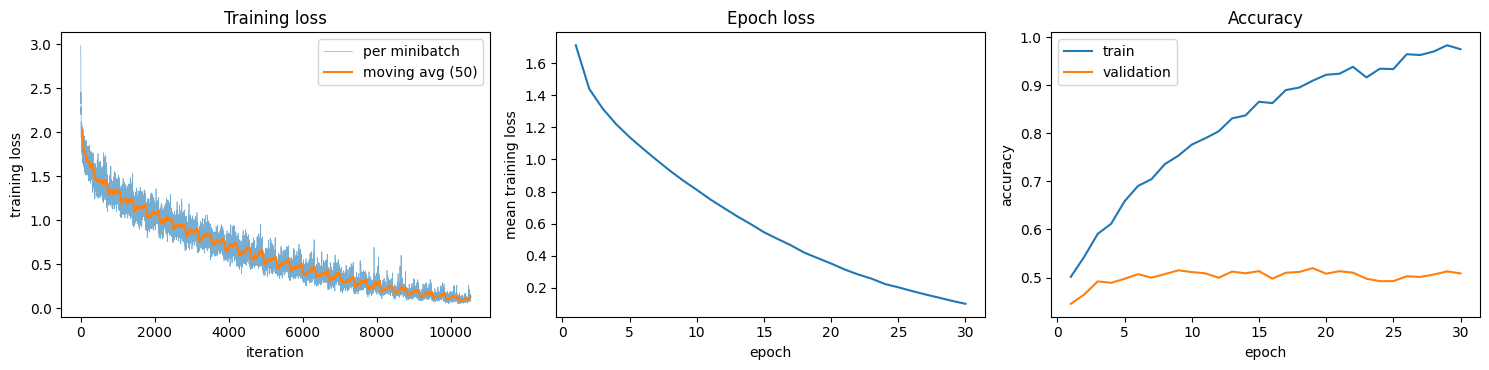

Final validation accuracy: 0.5086


In [4]:
EPOCHS = 2 if SMOKE else 30
BS, LR = 128, 0.03
Xf_tr, Xf_va = Xtr.flatten(1), Xva.flatten(1)
seed_all()
mlp = MLP([3072, 512, 256, 10], 'relu', 'he', dev=device)
hist = dict(loss=[], ep_loss=[], val_acc=[], train_acc=[])
for ep in range(EPOCHS):
    perm = torch.randperm(len(Xf_tr), device=device); tot = 0.; nb = 0
    for k in range(0, len(Xf_tr) - BS + 1, BS):
        idx = perm[k:k + BS]
        l = mlp.loss(Xf_tr[idx], ytr[idx]); mlp.backward(); mlp.sgd_step(LR)
        hist['loss'].append(l.item()); tot += l.item(); nb += 1
    hist['ep_loss'].append(tot / nb)
    hist['val_acc'].append((mlp.predict(Xf_va) == yva).float().mean().item())
    hist['train_acc'].append((mlp.predict(Xf_tr) == ytr).float().mean().item())
    print(f'epoch {ep+1:2d}  loss {hist["ep_loss"][-1]:.4f}  train acc {hist["train_acc"][-1]:.4f}  val acc {hist["val_acc"][-1]:.4f}')

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].plot(hist['loss'], lw=.5, alpha=.6, label='per minibatch')
sm = np.convolve(hist['loss'], np.ones(50) / 50, mode='valid'); ax[0].plot(np.arange(len(sm)) + 49, sm, label='moving avg (50)')
ax[0].set(xlabel='iteration', ylabel='training loss', title='Training loss'); ax[0].legend()
ax[1].plot(range(1, EPOCHS + 1), hist['ep_loss']); ax[1].set(xlabel='epoch', ylabel='mean training loss', title='Epoch loss')
ax[2].plot(range(1, EPOCHS + 1), hist['train_acc'], label='train'); ax[2].plot(range(1, EPOCHS + 1), hist['val_acc'], label='validation')
ax[2].set(xlabel='epoch', ylabel='accuracy', title='Accuracy'); ax[2].legend()
plt.tight_layout(); plt.show()
print(f'Final validation accuracy: {hist["val_acc"][-1]:.4f}')

### 1(d) Per-layer gradient norms in a 10-layer MLP at initialisation

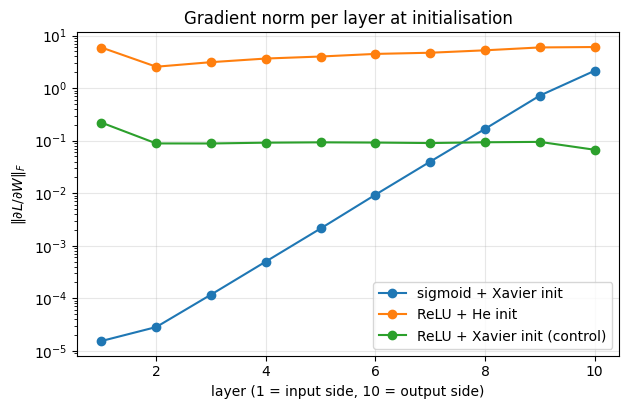

sigmoid + Xavier init            layer10 / layer1 gradient ratio = 1.39e+05
ReLU + He init                   layer10 / layer1 gradient ratio = 1.02e+00
ReLU + Xavier init (control)     layer10 / layer1 gradient ratio = 3.04e-01


In [5]:
def layer_grad_norms(act, init, seeds=5, bs=256):
    out = []
    for s in range(seeds):
        net = MLP([3072] + [256] * 9 + [10], act, init, dev=device, seed=s)
        idx = torch.randperm(len(Xf_tr), device=device)[:bs]
        net.loss(Xf_tr[idx], ytr[idx]); net.backward()
        out.append([l.dW.norm().item() for l in net.linears()])
    return np.mean(out, 0)

curves = {'sigmoid + Xavier init': layer_grad_norms('sigmoid', 'xavier'),
          'ReLU + He init': layer_grad_norms('relu', 'he'),
          'ReLU + Xavier init (control)': layer_grad_norms('relu', 'xavier')}
plt.figure(figsize=(7, 4.2))
for k, v in curves.items(): plt.semilogy(range(1, 11), v, 'o-', label=k)
plt.xlabel('layer (1 = input side, 10 = output side)'); plt.ylabel(r'$\|\partial L/\partial W\|_F$'); plt.grid(alpha=.3); plt.legend()
plt.title('Gradient norm per layer at initialisation'); plt.show()
for k, v in curves.items(): print(f'{k:32s} layer10 / layer1 gradient ratio = {v[-1]/v[0]:.2e}')

## Task 2 – Optimizers

### 2(a) SGD with momentum and Adam as `torch.optim.Optimizer` subclasses

In [6]:
class MySGD(torch.optim.Optimizer):
    """SGD with (heavy-ball) momentum, PyTorch convention: buf <- mu*buf + g ; p <- p - lr*buf  (momentum=0 gives plain SGD)."""
    def __init__(self, params, lr=1e-2, momentum=0., weight_decay=0.):
        super().__init__(params, dict(lr=lr, momentum=momentum, weight_decay=weight_decay))
    @torch.no_grad()
    def step(self):
        for g in self.param_groups:
            for p in g['params']:
                if p.grad is None: continue
                d = p.grad
                if g['weight_decay']: d = d + g['weight_decay'] * p            # L2 penalty
                if g['momentum']:
                    st = self.state[p]
                    if 'buf' not in st: st['buf'] = d.clone()                  # first step: buf = g
                    else: st['buf'].mul_(g['momentum']).add_(d)
                    d = st['buf']
                p.add_(d, alpha=-g['lr'])

class MyAdam(torch.optim.Optimizer):
    """Adam with bias correction: m_hat = m/(1-b1^t), v_hat = v/(1-b2^t), p <- p - lr*m_hat/(sqrt(v_hat)+eps)."""
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.):
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay))
    @torch.no_grad()
    def step(self):
        for g in self.param_groups:
            b1, b2 = g['betas']
            for p in g['params']:
                if p.grad is None: continue
                d = p.grad
                if g['weight_decay']: d = d + g['weight_decay'] * p
                st = self.state[p]
                if not st:
                    st['t'] = 0; st['m'] = torch.zeros_like(p); st['v'] = torch.zeros_like(p)
                st['t'] += 1; t = st['t']
                st['m'].mul_(b1).add_(d, alpha=1 - b1)
                st['v'].mul_(b2).addcmul_(d, d, value=1 - b2)
                m_hat = st['m'] / (1 - b1 ** t); v_hat = st['v'] / (1 - b2 ** t)
                p.addcdiv_(m_hat, v_hat.sqrt().add_(g['eps']), value=-g['lr'])

**Equivalence test.** Same tiny network, same data, same initialisation, 100 steps, `float64`. We compare every
parameter after training with `torch.allclose` and print the largest absolute difference (also the loss trace).

In [7]:
def run_opt(make_opt, steps=100):
    torch.manual_seed(0)
    model = nn.Sequential(nn.Linear(10, 16), nn.Tanh(), nn.Linear(16, 1)).double()
    X = torch.randn(64, 10, dtype=torch.float64, generator=torch.Generator().manual_seed(1))
    Y = torch.sin(X.sum(1, keepdim=True))
    opt = make_opt(model.parameters()); losses = []
    for _ in range(steps):
        loss = F.mse_loss(model(X), Y); opt.zero_grad(); loss.backward(); opt.step(); losses.append(loss.item())
    return torch.cat([p.detach().flatten() for p in model.parameters()]), losses

tests = {
 'SGD (mu=0)':           (lambda p: MySGD(p, lr=0.05),                                    lambda p: torch.optim.SGD(p, lr=0.05)),
 'SGD + momentum 0.9':   (lambda p: MySGD(p, lr=0.05, momentum=0.9),                      lambda p: torch.optim.SGD(p, lr=0.05, momentum=0.9)),
 'SGD + mom + wd':       (lambda p: MySGD(p, lr=0.05, momentum=0.9, weight_decay=1e-3),   lambda p: torch.optim.SGD(p, lr=0.05, momentum=0.9, weight_decay=1e-3)),
 'Adam':                 (lambda p: MyAdam(p, lr=1e-2),                                   lambda p: torch.optim.Adam(p, lr=1e-2)),
 'Adam + wd (L2)':       (lambda p: MyAdam(p, lr=1e-2, weight_decay=1e-3),                lambda p: torch.optim.Adam(p, lr=1e-2, weight_decay=1e-3)),
}
rows = []
for name, (mine, ref) in tests.items():
    a, la = run_opt(mine); b, lb = run_opt(ref)
    rows.append((name, (a - b).abs().max().item(), abs(la[-1] - lb[-1]), torch.allclose(a, b, rtol=1e-9, atol=1e-10)))
import pandas as pd
pd.set_option('display.float_format', lambda v: f'{v:.2e}')
display(pd.DataFrame(rows, columns=['optimizer', 'max |param diff|', '|final loss diff|', 'allclose']))
assert all(r[3] for r in rows)

,optimizer,max |param diff|,|final loss diff|,allclose
0,SGD (mu=0),0.00e+00,0.00e+00,True
1,SGD + momentum 0.9,0.00e+00,0.00e+00,True
2,SGD + mom + wd,2.22e-16,1.39e-17,True
3,Adam,1.48e-15,5.20e-18,True
4,Adam + wd (L2),3.00e-15,6.07e-18,True


### 2(b) Trajectories on the ill-conditioned quadratic $f(x,y)=\tfrac12(x^2+50y^2)$


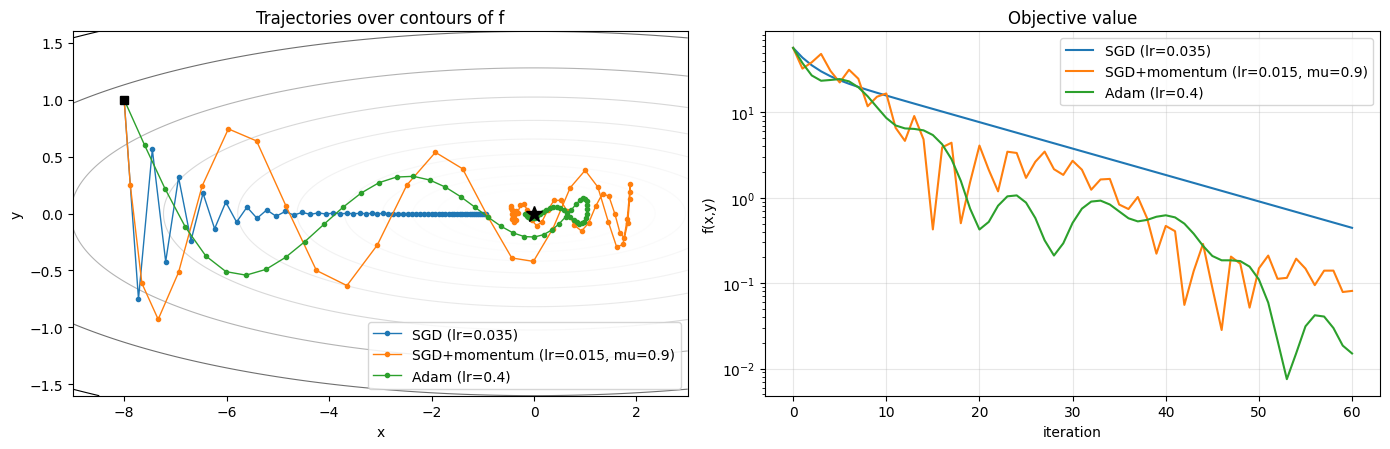

SGD (lr=0.035)                     final f = 4.451e-01   final point = (-0.943, 0.000)
SGD+momentum (lr=0.015, mu=0.9)    final f = 8.121e-02   final point = (-0.357, 0.026)
Adam (lr=0.4)                      final f = 1.503e-02   final point = (-0.172, -0.003)


In [8]:
def f(p): return 0.5 * (p[0] ** 2 + 50 * p[1] ** 2)
def trajectory(make_opt, start=(-8., 1.), steps=60):
    p = torch.tensor(start, requires_grad=True); opt = make_opt([p]); path = [p.detach().clone().numpy()]; vals = [f(p).item()]
    for _ in range(steps):
        loss = f(p); opt.zero_grad(); loss.backward(); opt.step()
        path.append(p.detach().clone().numpy()); vals.append(f(p).item())
    return np.array(path), np.array(vals)

runs = {'SGD (lr=0.035)':                 trajectory(lambda p: MySGD(p, lr=0.035)),
        'SGD+momentum (lr=0.015, mu=0.9)': trajectory(lambda p: MySGD(p, lr=0.015, momentum=0.9)),
        'Adam (lr=0.4)':                  trajectory(lambda p: MyAdam(p, lr=0.4))}
xs = np.linspace(-9, 3, 400); ys = np.linspace(-1.6, 1.6, 400); XX, YY = np.meshgrid(xs, ys)
ZZ = 0.5 * (XX ** 2 + 50 * YY ** 2)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
ax[0].contour(XX, YY, ZZ, levels=np.geomspace(0.05, 100, 18), cmap='Greys', linewidths=.8)
for (k, (path, vals)), c in zip(runs.items(), ['C0', 'C1', 'C2']):
    ax[0].plot(path[:, 0], path[:, 1], 'o-', ms=3, lw=1, color=c, label=k)
ax[0].plot(0, 0, 'k*', ms=12); ax[0].plot(-8, 1, 'ks'); ax[0].set(xlabel='x', ylabel='y', title='Trajectories over contours of f'); ax[0].legend(loc='lower right')
for k, (path, vals) in runs.items(): ax[1].semilogy(vals + 1e-12, label=k)
ax[1].set(xlabel='iteration', ylabel='f(x,y)', title='Objective value'); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()
for k, (path, vals) in runs.items(): print(f'{k:34s} final f = {vals[-1]:.3e}   final point = ({path[-1][0]:.3f}, {path[-1][1]:.3f})')

### 2(c) Small CNN (no BatchNorm): optimizer × learning rate
3 conv blocks → 2 FC layers, trained for a few epochs on the 45k training images with each optimizer at three learning rates
(spaced by 10x). Runs that blow up are marked as diverged (validation accuracy = 10%).

== SGD  lr=0.003
   final train loss 1.6814  val acc 0.3926
== SGD  lr=0.03
   final train loss 0.8010  val acc 0.6866
== SGD  lr=0.3
   final train loss 0.2395  val acc 0.7206
== SGD+momentum  lr=0.001
   final train loss 1.1980  val acc 0.5644
== SGD+momentum  lr=0.01
   final train loss 0.3211  val acc 0.7534
== SGD+momentum  lr=0.1
   final train loss 1.1704  val acc 0.5716
== Adam  lr=0.0001
   final train loss 0.9684  val acc 0.6462
== Adam  lr=0.001
   final train loss 0.1941  val acc 0.7482
== Adam  lr=0.01
   final train loss 2.3032  val acc 0.0934


,optimizer,lr,val acc,final train loss
0,SGD,0.003,0.3926,1.681
1,SGD,0.03,0.6866,0.801
2,SGD,0.3,0.7206,0.2395
3,SGD+momentum,0.001,0.5644,1.198
4,SGD+momentum,0.01,0.7534,0.3211
5,SGD+momentum,0.1,0.5716,1.17
6,Adam,0.0001,0.6462,0.9684
7,Adam,0.001,0.7482,0.1941
8,Adam,0.01,0.0934,2.303


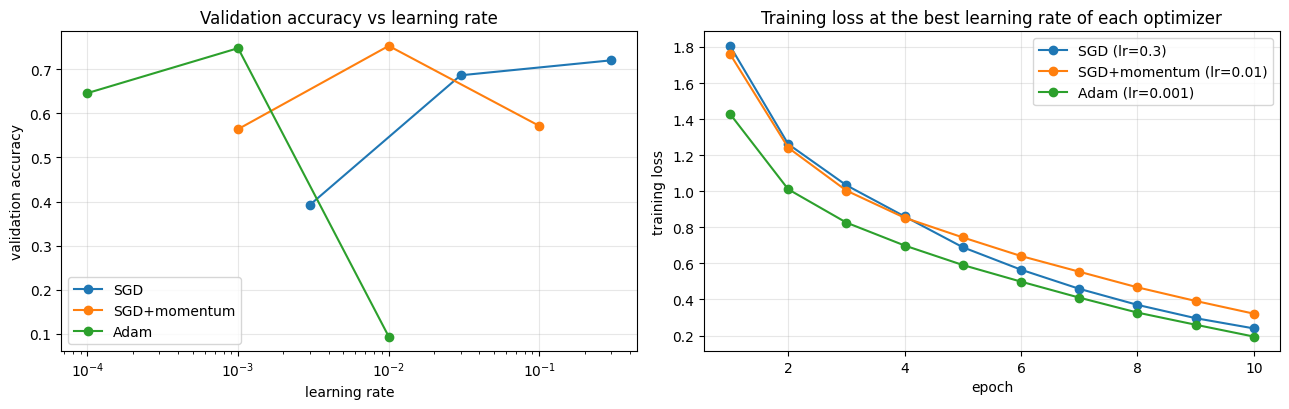

In [9]:
EPOCHS_C = 1 if SMOKE else 10
grid = {'SGD':          (lambda p, lr: MySGD(p, lr=lr),                  [0.003, 0.03, 0.3]),
        'SGD+momentum': (lambda p, lr: MySGD(p, lr=lr, momentum=0.9),    [0.001, 0.01, 0.1]),
        'Adam':         (lambda p, lr: MyAdam(p, lr=lr),                 [1e-4, 1e-3, 1e-2])}
results = {}   # (opt, lr) -> history
for name, (mk, lrs) in grid.items():
    for lr in lrs:
        seed_all(); model = SmallCNN(bn=False)
        print(f'== {name}  lr={lr}')
        results[(name, lr)] = train_model(model, mk(model.parameters(), lr), EPOCHS_C, bs=128, verbose=False)
        h = results[(name, lr)]
        print('   diverged' if h['diverged'] else f'   final train loss {h["train_loss"][-1]:.4f}  val acc {h["val_acc"][-1]:.4f}')

def final_val(h): return 0.10 if (h['diverged'] or not h['val_acc']) else h['val_acc'][-1]
import pandas as pd
tab = pd.DataFrame([(n, lr, final_val(h), h['train_loss'][-1] if h['train_loss'] else float('nan')) for (n, lr), h in results.items()],
                   columns=['optimizer', 'lr', 'val acc', 'final train loss'])
pd.set_option('display.float_format', lambda v: f'{v:.4g}'); display(tab)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for name, (mk, lrs) in grid.items():
    ax[0].plot(lrs, [final_val(results[(name, lr)]) for lr in lrs], 'o-', label=name)
ax[0].set(xscale='log', xlabel='learning rate', ylabel='validation accuracy', title='Validation accuracy vs learning rate'); ax[0].grid(alpha=.3); ax[0].legend()
for name, (mk, lrs) in grid.items():
    best = max(lrs, key=lambda lr: final_val(results[(name, lr)])); h = results[(name, best)]
    ax[1].plot(range(1, len(h['train_loss']) + 1), h['train_loss'], 'o-', label=f'{name} (lr={best})')
ax[1].set(xlabel='epoch', ylabel='training loss', title='Training loss at the best learning rate of each optimizer'); ax[1].grid(alpha=.3); ax[1].legend()
plt.tight_layout(); plt.show()

## Task 3 – Regularisation and residual connections

### 3(a) Small CNN with BatchNorm on only 5k training images
Train subset = first 5 000 images of the (shuffled) 45k training split; validation = the full 5k validation split.
Same optimiser / schedule for every variant: SGD (momentum 0.9, Nesterov), lr 0.05 with cosine decay, batch 128.
Train accuracy is measured in eval mode on the **clean** 5k training images, so it is comparable across variants.
`cutout` and `mixup` are my own implementations (see the common cell: `cutout()` zeroes a 16x16 square; `mixup()` mixes
pairs with `lambda ~ Beta(0.4, 0.4)` and mixes the loss).

== baseline
   train 1.0000  val 0.6616
== weight decay
   train 1.0000  val 0.6572
== dropout
   train 0.8342  val 0.6622
== flip+crop
   train 0.9660  val 0.7272
== cutout
   train 1.0000  val 0.6790
== mixup
   train 1.0000  val 0.6364
== all combined
   train 0.5916  val 0.5628


,method,train acc,val acc,gap (train-val),best val acc (any epoch)
0,baseline,1.0000,0.6616,0.3384,0.6626
1,weight decay,1.0000,0.6572,0.3428,0.6582
2,dropout,0.8342,0.6622,0.1720,0.6622
3,flip+crop,0.9660,0.7272,0.2388,0.7308
4,cutout,1.0000,0.6790,0.3210,0.6814
5,mixup,1.0000,0.6364,0.3636,0.6474
6,all combined,0.5916,0.5628,0.0288,0.5686


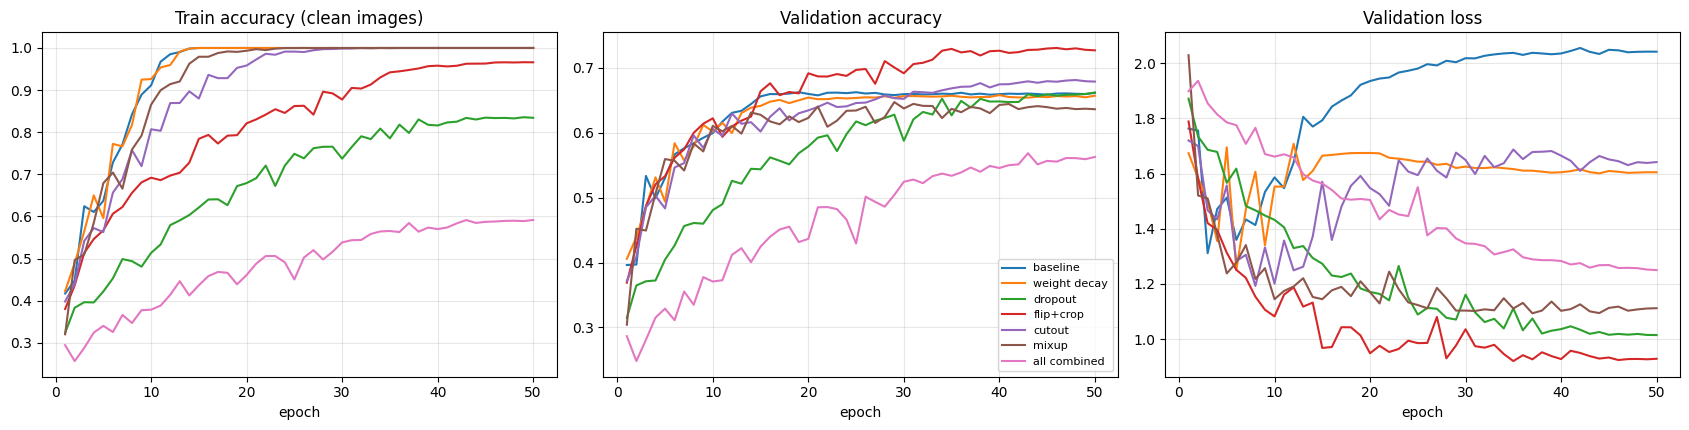

In [10]:
NSUB = 500 if SMOKE else 5000
EPOCHS_A = 2 if SMOKE else 50
Xs, ys = Xtr[:NSUB], ytr[:NSUB]
configs = {
    'baseline':     dict(wd=0,    dropout=False, augs=(),                  mix=0.),
    'weight decay': dict(wd=5e-4, dropout=False, augs=(),                  mix=0.),
    'dropout':      dict(wd=0,    dropout=True,  augs=(),                  mix=0.),
    'flip+crop':    dict(wd=0,    dropout=False, augs=('flip', 'crop'),    mix=0.),
    'cutout':       dict(wd=0,    dropout=False, augs=('cutout',),         mix=0.),
    'mixup':        dict(wd=0,    dropout=False, augs=(),                  mix=0.4),
    'all combined': dict(wd=5e-4, dropout=True,  augs=('flip', 'crop', 'cutout'), mix=0.4),
}
hists_a = {}
for name, c in configs.items():
    seed_all(); model = SmallCNN(bn=True, dropout=c['dropout']).to(device)
    opt = torch.optim.SGD(model.parameters(), lr=0.05, momentum=0.9, nesterov=True, weight_decay=c['wd'])
    steps = EPOCHS_A * (NSUB // 128)
    print(f'== {name}')
    hists_a[name] = train_model(model, opt, EPOCHS_A, Xtr=Xs, ytr=ys, bs=128, augs=c['augs'], mixup_alpha=c['mix'],
                                sched=cosine_warmup(opt, steps), eval_train=True, verbose=False)
    h = hists_a[name]; print(f'   train {h["train_acc"][-1]:.4f}  val {h["val_acc"][-1]:.4f}')

import pandas as pd
rows = [(n, h['train_acc'][-1], h['val_acc'][-1], h['train_acc'][-1] - h['val_acc'][-1], max(h['val_acc'])) for n, h in hists_a.items()]
tab_a = pd.DataFrame(rows, columns=['method', 'train acc', 'val acc', 'gap (train-val)', 'best val acc (any epoch)'])
pd.set_option('display.float_format', lambda v: f'{v:.4f}'); display(tab_a)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.4))
for n, h in hists_a.items():
    e = range(1, len(h['val_acc']) + 1)
    ax[0].plot(e, h['train_acc'], label=n); ax[1].plot(e, h['val_acc'], label=n); ax[2].plot(e, h['val_loss'], label=n)
ax[0].set(title='Train accuracy (clean images)', xlabel='epoch'); ax[1].set(title='Validation accuracy', xlabel='epoch')
ax[2].set(title='Validation loss', xlabel='epoch'); ax[1].legend(fontsize=8)
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.show()

### 3(b) Plain vs residual networks of depth 6n+2 (8, 20, 56)

== depth 8 plain  (75k params)
  ep   1/10 train_loss 1.6776 val_loss 1.5312 val_acc 0.4552 (5.4s)
  ep   2/10 train_loss 1.1475 val_loss 1.1264 val_acc 0.5972 (1.9s)
  ep   3/10 train_loss 0.9706 val_loss 1.2663 val_acc 0.5746 (1.9s)
  ep   4/10 train_loss 0.8666 val_loss 0.9959 val_acc 0.6530 (1.9s)
  ep   5/10 train_loss 0.7953 val_loss 0.9258 val_acc 0.6826 (1.9s)
  ep   6/10 train_loss 0.7340 val_loss 0.8986 val_acc 0.6990 (1.9s)
  ep   7/10 train_loss 0.6707 val_loss 0.6772 val_acc 0.7658 (1.9s)
  ep   8/10 train_loss 0.6209 val_loss 0.6369 val_acc 0.7824 (1.9s)
  ep   9/10 train_loss 0.5796 val_loss 0.5789 val_acc 0.8022 (1.9s)
  ep  10/10 train_loss 0.5533 val_loss 0.5750 val_acc 0.8046 (1.9s)
== depth 8 residual  (78k params)
  ep   1/10 train_loss 1.6661 val_loss 1.5376 val_acc 0.4758 (2.3s)
  ep   2/10 train_loss 1.1829 val_loss 1.1846 val_acc 0.5756 (2.2s)
  ep   3/10 train_loss 1.0086 val_loss 1.0713 val_acc 0.6200 (2.2s)
  ep   4/10 train_loss 0.9030 val_loss 0.9900 val_a

/tmp/ipykernel_23/408083185.py:113: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  if sched is not None: sched.step()


  ep   1/10 train_loss 2.2188 val_loss 2.0107 val_acc 0.2248 (10.5s)
  ep   2/10 train_loss 1.9435 val_loss 1.9891 val_acc 0.2730 (10.5s)
  ep   3/10 train_loss 1.8535 val_loss 1.8291 val_acc 0.3226 (10.5s)
  ep   4/10 train_loss 1.7749 val_loss 1.9536 val_acc 0.2662 (10.5s)
  ep   5/10 train_loss 1.6884 val_loss 1.8193 val_acc 0.3294 (10.6s)
  ep   6/10 train_loss 1.5872 val_loss 1.5434 val_acc 0.4236 (10.6s)
  ep   7/10 train_loss 1.4933 val_loss 1.4960 val_acc 0.4528 (10.5s)
  ep   8/10 train_loss 1.3934 val_loss 1.3577 val_acc 0.5028 (10.5s)
  ep   9/10 train_loss 1.3087 val_loss 1.2378 val_acc 0.5514 (10.5s)
  ep  10/10 train_loss 1.2577 val_loss 1.2129 val_acc 0.5636 (10.6s)
== depth 56 residual  (856k params)
  ep   1/10 train_loss 1.8015 val_loss 1.5302 val_acc 0.4756 (11.4s)
  ep   2/10 train_loss 1.1897 val_loss 1.2886 val_acc 0.5702 (11.5s)
  ep   3/10 train_loss 0.8920 val_loss 0.9303 val_acc 0.6752 (11.4s)
  ep   4/10 train_loss 0.7426 val_loss 0.7426 val_acc 0.7450 (11.4s

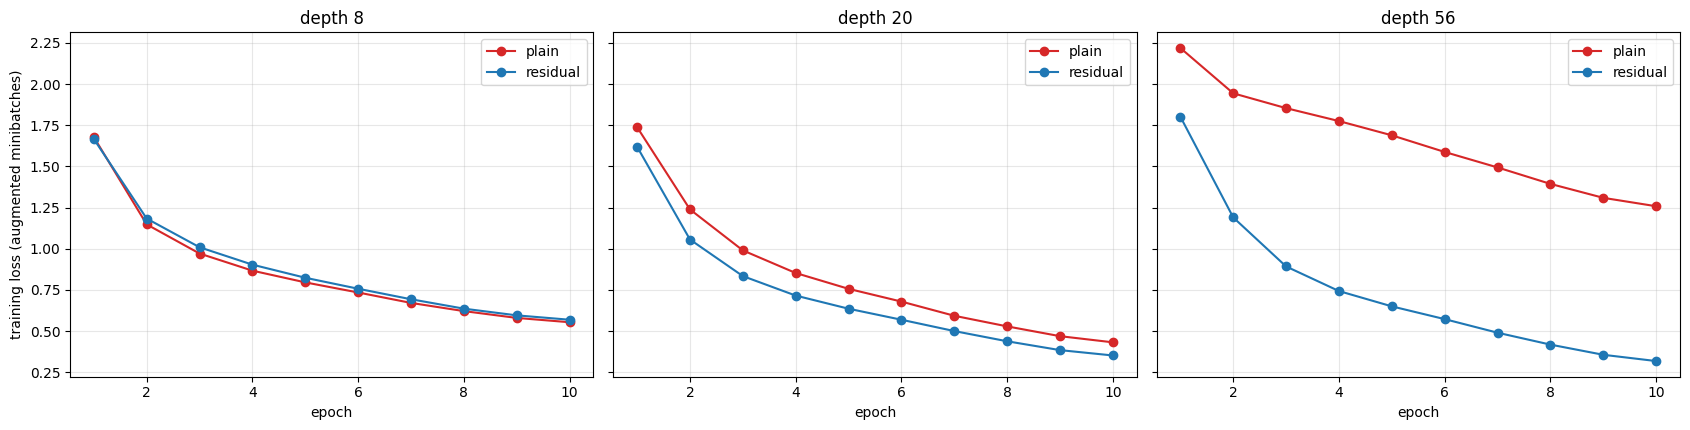

,depth,family,params,final train loss,final val acc,diverged
0,8,plain,75290,0.5533,0.8046,False
1,8,residual,78042,0.5685,0.7996,False
2,20,plain,269722,0.4313,0.8416,False
3,20,residual,272474,0.3515,0.8612,False
4,56,plain,853018,1.2577,0.5636,False
5,56,residual,855770,0.3176,0.8672,False


In [11]:
EPOCHS_B = 1 if SMOKE else 10
depths = {8: 1, 20: 3, 56: 9}
hists_b = {}; params_b = {}
for d, n in depths.items():
    for res in (False, True):
        seed_all(); model = CifarNet(n, residual=res).to(device)
        if device.type == 'cuda': model = model.to(memory_format=torch.channels_last)
        key = (d, 'residual' if res else 'plain'); params_b[key] = count_params(model)
        opt = torch.optim.SGD(model.parameters(), lr=0.1, momentum=0.9, nesterov=True, weight_decay=5e-4)
        spe = len(Xtr) // 128
        print(f'== depth {d} {key[1]}  ({params_b[key]/1e3:.0f}k params)')
        hists_b[key] = train_model(model, opt, EPOCHS_B, bs=128, augs=('flip', 'crop'), amp=True,
                                   sched=cosine_warmup(opt, EPOCHS_B * spe, warmup_steps=spe), verbose=True)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.4), sharey=True)
for a, d in zip(ax, depths):
    for kind, c in (('plain', 'C3'), ('residual', 'C0')):
        h = hists_b[(d, kind)]; a.plot(range(1, len(h['train_loss']) + 1), h['train_loss'], 'o-', color=c, label=kind)
    a.set(title=f'depth {d}', xlabel='epoch'); a.grid(alpha=.3); a.legend()
ax[0].set_ylabel('training loss (augmented minibatches)'); plt.tight_layout(); plt.show()

import pandas as pd
rows = [(d, k, params_b[(d, k)], (h := hists_b[(d, k)])['train_loss'][-1] if hists_b[(d, k)]['train_loss'] else float('nan'),
         hists_b[(d, k)]['val_acc'][-1] if hists_b[(d, k)]['val_acc'] else float('nan'), hists_b[(d, k)]['diverged'])
        for d in depths for k in ('plain', 'residual')]
display(pd.DataFrame(rows, columns=['depth', 'family', 'params', 'final train loss', 'final val acc', 'diverged']))

## Task 4 (optional) – Best CNN with ≤ 500k parameters and ≤ 20 epochs
**Design.** A CIFAR-style residual network (depth 6n+2, 3 stages, global average pooling, BatchNorm, Kaiming init) – the
family from Task 3, which is parameter-efficient because it has no large FC layers and trains well thanks to shortcuts.
The width was increased from 16/32/64 to 20/40/80 (n=3, ResNet-20 layout) to use the parameter budget.
Training recipe: SGD + Nesterov momentum 0.9, one-cycle-like schedule (linear warm-up for 2 epochs, cosine decay), peak lr 0.2,
batch 128, weight decay 5e-4, label smoothing 0.1, flip + crop + cutout, mixed precision, **20 epochs**.
Every choice is tuned / ablated on the **validation split only**; the test set is touched exactly once at the very end.

In [12]:
EPOCHS_F = 1 if SMOKE else 20
MAX_PARAMS, MAX_EPOCHS = 500_000, 20
assert EPOCHS_F <= MAX_EPOCHS

def make_net(n=3, widths=(20, 40, 80), residual=True):
    m = CifarNet(n, residual=residual, widths=widths)
    assert count_params(m) <= MAX_PARAMS, count_params(m)
    return m

base = dict(n=3, widths=(20, 40, 80), residual=True, opt='sgd', lr=0.2, wd=5e-4, augs=('flip', 'crop', 'cutout'), ls=0.1)
print('parameters of final architecture:', count_params(make_net()))

def run_experiment(cfg, epochs=EPOCHS_F, verbose=False):
    seed_all()
    model = make_net(cfg['n'], cfg['widths'], cfg['residual']).to(device)
    if device.type == 'cuda': model = model.to(memory_format=torch.channels_last)
    if cfg['opt'] == 'sgd': opt = torch.optim.SGD(model.parameters(), lr=cfg['lr'], momentum=0.9, nesterov=True, weight_decay=cfg['wd'])
    else:                   opt = torch.optim.AdamW(model.parameters(), lr=cfg['lr'], weight_decay=cfg['wd'])   # decoupled wd for Adam
    spe = len(Xtr) // 128
    h = train_model(model, opt, epochs, bs=128, augs=cfg['augs'], label_smoothing=cfg['ls'], amp=True,
                    sched=cosine_warmup(opt, epochs * spe, warmup_steps=2 * spe if epochs > 2 else spe), verbose=verbose)
    return model, h

parameters of final architecture: 424910


== FULL recipe
   val acc 0.8984   train loss 0.7904
== no shortcut (plain net)
   val acc 0.8700   train loss 0.8667
== no augmentation
   val acc 0.8728   train loss 0.5165
== no cutout (flip+crop only)
   val acc 0.9090   train loss 0.6394
== no weight decay
   val acc 0.8802   train loss 0.8204
== AdamW (lr 2e-3) instead of SGD
   val acc 0.8844   train loss 0.8387
== no label smoothing
   val acc 0.8924   train loss 0.3511
== deeper/thinner (n=5, 16/32/64)
   val acc 0.8958   train loss 0.7983


,variant,params,val acc,Δ vs FULL,final train loss
0,FULL recipe,424910,0.8984,0.0000,0.7904
1,no shortcut (plain net),420670,0.8700,-0.0284,0.8667
2,no augmentation,424910,0.8728,-0.0256,0.5165
3,no cutout (flip+crop only),424910,0.9090,0.0106,0.6394
4,no weight decay,424910,0.8802,-0.0182,0.8204
5,AdamW (lr 2e-3) instead of SGD,424910,0.8844,-0.0140,0.8387
6,no label smoothing,424910,0.8924,-0.0060,0.3511
7,"deeper/thinner (n=5, 16/32/64)",466906,0.8958,-0.0026,0.7983


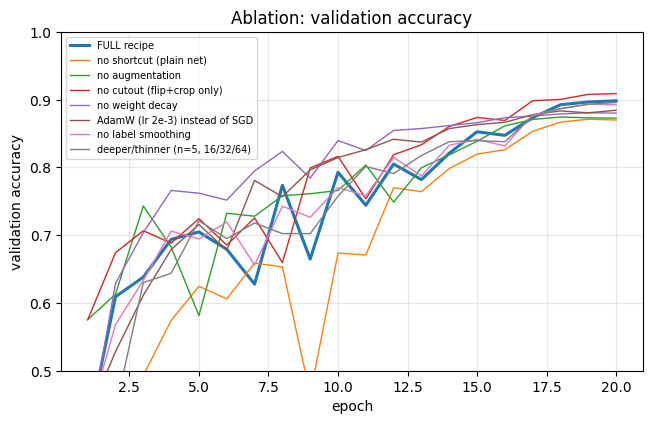

In [13]:
variants = {
    'FULL recipe':                 {},
    'no shortcut (plain net)':     dict(residual=False),
    'no augmentation':             dict(augs=()),
    'no cutout (flip+crop only)':  dict(augs=('flip', 'crop')),
    'no weight decay':             dict(wd=0.),
    'AdamW (lr 2e-3) instead of SGD': dict(opt='adamw', lr=2e-3, wd=5e-2),
    'no label smoothing':          dict(ls=0.),
    'deeper/thinner (n=5, 16/32/64)': dict(n=5, widths=(16, 32, 64)),
}
abl = {}; final_model = None
for name, ch in variants.items():
    cfg = {**base, **ch}; print(f'== {name}')
    model, h = run_experiment(cfg, verbose=False)
    abl[name] = dict(params=count_params(model), val_acc=h['val_acc'][-1] if h['val_acc'] else float('nan'),
                     train_loss=h['train_loss'][-1] if h['train_loss'] else float('nan'), hist=h)
    print(f'   val acc {abl[name]["val_acc"]:.4f}   train loss {abl[name]["train_loss"]:.4f}')
    if name == 'FULL recipe': final_model = model            # keep the trained model for the single test evaluation

import pandas as pd
ref = abl['FULL recipe']['val_acc']
tab4 = pd.DataFrame([(k, v['params'], v['val_acc'], v['val_acc'] - ref, v['train_loss']) for k, v in abl.items()],
                    columns=['variant', 'params', 'val acc', 'Δ vs FULL', 'final train loss'])
pd.set_option('display.float_format', lambda v: f'{v:.4f}'); display(tab4)

plt.figure(figsize=(7.5, 4.4))
for k, v in abl.items(): plt.plot(range(1, len(v['hist']['val_acc']) + 1), v['hist']['val_acc'], label=k, lw=2.2 if k == 'FULL recipe' else 1)
plt.xlabel('epoch'); plt.ylabel('validation accuracy'); plt.ylim(0.5, 1.0); plt.grid(alpha=.3); plt.legend(fontsize=7); plt.title('Ablation: validation accuracy'); plt.show()

### Final evaluation on the test set – done **once**
The model is the already trained `FULL recipe` model (trained on the 45k split only; no retraining on train+val, no re-tuning
after looking at the test result). The guard below prevents accidental repeated use of the test set.

In [14]:
_TEST_USED = False
def evaluate_on_test_once(model):
    global _TEST_USED
    assert not _TEST_USED, 'The test set may only be used once!'
    _TEST_USED = True
    if SMOKE:
        g = torch.Generator().manual_seed(5); Xt = torch.rand(200, 3, 32, 32, generator=g); yt = torch.randint(0, 10, (200,), generator=g)
    else:
        import torchvision
        ds = torchvision.datasets.CIFAR10('./data', train=False, download=True)
        Xt = torch.from_numpy(ds.data).permute(0, 3, 1, 2).float() / 255.; yt = torch.tensor(ds.targets)
    Xt = ((Xt - MEAN) / STD).to(device); yt = yt.to(device)           # TRAINING mean/std
    return evaluate(model, Xt, yt)

test_loss, test_acc = evaluate_on_test_once(final_model)
print(f'Final model: {count_params(final_model):,} parameters, {EPOCHS_F} epochs')
print(f'Validation accuracy: {abl["FULL recipe"]["val_acc"]:.4f}   |   TEST accuracy (evaluated once): {test_acc:.4f}   (test loss {test_loss:.4f})')

Final model: 424,910 parameters, 20 epochs
Validation accuracy: 0.8984   |   TEST accuracy (evaluated once): 0.8970   (test loss 0.3590)
